# Common support and conditional shift

If there is indeed conditional shift between the simulations, the inferred masses should be different for comparable simulation populations.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'pyproject.toml').is_file())
def table(relative):
    return pd.read_csv(ROOT / 'results' / relative)
def saved_json(relative):
    return json.loads((ROOT / 'results' / relative).read_text(encoding='utf-8'))
plt.rcParams.update({'figure.figsize': (9, 4), 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_rows', 40)
pd.set_option('display.max_columns', 16)

A histogram gradient-boosted classifier distinguishes FLAMINGO=0 from TNG300=1,
with inverse-frequency weights giving each domain equal total weight. Five-fold
connected-host-component cross-fitting produces feature-only out-of-fold scores.
The main overlap band is 0.4≤s(x)≤0.6, with sensitivity to wider/narrower bands.

The classifier uses 160 boosting iterations, learning rate 0.06, at most 15 leaves,
minimum 30 rows per leaf and L2 regularization 1. A score near 0.5 defines the tested
classifier overlap, not exact equality of all covariates or proof of physical similarity.
This experiment covers dynamics and mass variants; it is not a morphology common-support test.


In [2]:
display(table('competing/classifier_discrimination.csv'))
common=table('competing/common_support_main.csv')
display(common[['model','population','subset','half_width','n_total','n','retained_fraction','rmse','bias','coverage68','coverage95']])
display(table('competing/retention_all_bands.csv').query('half_width == 0.1'))

,feature_space,n_flamingo,n_tng,roc_auc,balanced_accuracy_at_0.5,median_score_flamingo,median_score_tng
0,dynamics,142713,1530,0.631640,0.597957,0.503116,0.548673
1,bound_subhalo_ratio,142713,1530,0.688261,0.639033,0.470879,0.587148
2,stellar_individual,142713,1530,0.811777,0.739506,0.305447,0.694358
3,stellar_ratio,142713,1530,0.647863,0.608256,0.487846,0.559031
4,stellar_sum,142713,1530,0.809069,0.737813,0.311759,0.702150


,model,population,subset,half_width,n_total,n,retained_fraction,rmse,bias,coverage68,coverage95
0,m200c_dynamics,source_heldout,pooled,0.1,21409,12055,0.563081,0.244069,-0.000115,0.712733,0.939361
1,m200c_dynamics,transfer_tng,pooled,0.1,1530,957,0.625490,0.376529,-0.156702,0.669801,0.855799
2,m200c_dynamics,transfer_tng,pooled,0.5,1530,1530,1.000000,0.368396,-0.152923,0.666667,0.866667
3,m200c_bound_ratio,source_heldout,pooled,0.1,21409,8209,0.383437,0.161860,-0.000240,0.676818,0.946035
4,m200c_bound_ratio,transfer_tng,pooled,0.1,1530,629,0.411111,0.205622,-0.110496,0.626391,0.901431
5,m200c_bound_ratio,transfer_tng,pooled,0.5,1530,1530,1.000000,0.201451,-0.108417,0.643791,0.890196
6,m200c_stellar_individual,source_heldout,pooled,0.1,21409,4215,0.196880,0.132314,0.004512,0.691578,0.954686
7,m200c_stellar_individual,transfer_tng,pooled,0.1,1530,298,0.194771,0.342168,-0.295580,0.191275,0.469799
8,m200c_stellar_individual,transfer_tng,pooled,0.5,1530,1530,1.000000,0.331409,-0.288805,0.198039,0.545098
9,m200c_stellar_ratio,source_heldout,pooled,0.1,21409,10594,0.494839,0.209297,-0.009547,0.701907,0.946857


,feature_space,simulation,subset,half_width,score_interval,n_total,n_retained,retained_fraction
1,dynamics,flamingo,pooled,0.1,0.40-0.60,21409,12055,0.563081
8,dynamics,flamingo,same_host,0.1,0.40-0.60,9464,5868,0.620034
15,dynamics,flamingo,different_host,0.1,0.40-0.60,11945,6187,0.517957
22,dynamics,tng,pooled,0.1,0.40-0.60,1530,957,0.625490
29,dynamics,tng,same_host,0.1,0.40-0.60,1253,774,0.617717
36,dynamics,tng,different_host,0.1,0.40-0.60,277,183,0.660650
43,bound_subhalo_ratio,flamingo,pooled,0.1,0.40-0.60,21409,8209,0.383437
50,bound_subhalo_ratio,flamingo,same_host,0.1,0.40-0.60,9464,3954,0.417794
57,bound_subhalo_ratio,flamingo,different_host,0.1,0.40-0.60,11945,4255,0.356216
64,bound_subhalo_ratio,tng,pooled,0.1,0.40-0.60,1530,629,0.411111


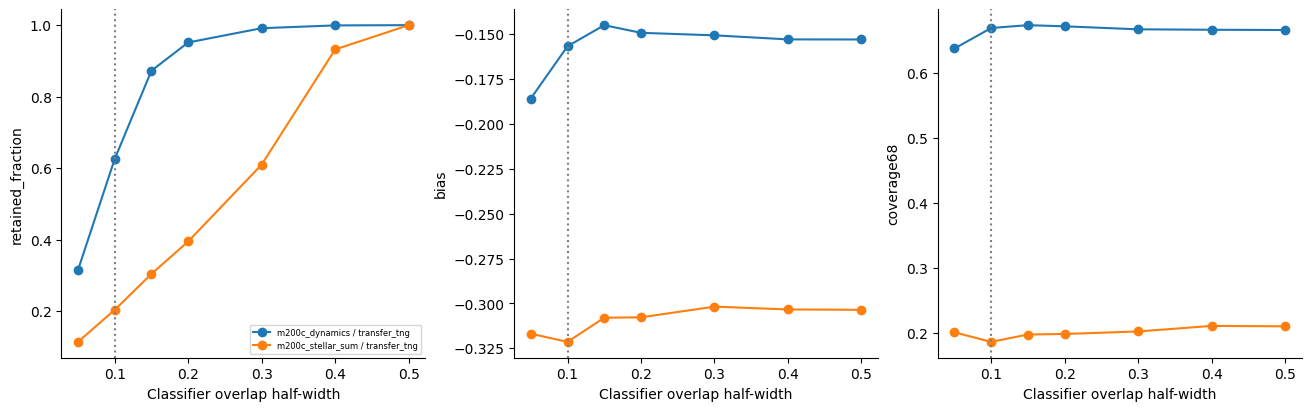

In [3]:
sensitivity=table('competing/common_support_band_sensitivity.csv')
use=sensitivity.query("subset == 'pooled'")
fig,axes=plt.subplots(1,3,figsize=(13,4),layout='constrained')
for (model,population),part in use.groupby(['model','population']):
    if 'stellar_sum' not in model and 'dynamics' not in model: continue
    part=part.sort_values('half_width')
    for ax,metric in zip(axes,['retained_fraction','bias','coverage68']):
        ax.plot(part.half_width,part[metric],'o-',label=model+' / '+population)
for ax,metric in zip(axes,['retained_fraction','bias','coverage68']):
    ax.axvline(.1,color='gray',ls=':');ax.set(xlabel='Classifier overlap half-width',ylabel=metric)
axes[0].legend(fontsize=6);plt.show()

Absolute-stellar transfer bias remains in the populations. This argues against
an explanation based only on coarse feature-support differences under this classifier,
while finite classifier accuracy and shrinking test populations limit the inference.
Inspect retained counts, target ranges and widths together with accuracy: changing
the band also changes the evaluated population.

The starting populations are 21409 FLAMINGO held-out rows and all 1530 TNG rows,
distinct from the final-six 231-row TNG test. The domain classifier is grouped out-of-fold;
it does not fit on target masses. Notebook 13 uses a later train/validation/test-calibrated
diagnostic classifier and should not be confused with these OOF scores.

The [common-support workflow](../research/notebooks/original/domain_common_support.ipynb)
and [conditional mapping](../research/notebooks/original/conditional_mapping_common_support.ipynb).


[Previous](09_stellar_normalization.ipynb) · [Next](11_prior_and_support_sensitivity.ipynb) · [Repository map](../README.md)
